# DNN Assignment 2 - Problem 1: RNN, LSTM and GRU

**Name:** Amit Kumar Mohanty&nbsp;&nbsp; **Student ID:** 2026AJ05290

Here I write RNN, LSTM and GRU cells myself, check them against PyTorch, and then compare the three
models on HAR (phone sensor data) and on the adding problem (a memory test).

My choices: h = 64 for all three models, seeds 11, 23, 37. My ID ends in 0 (even), so my ablation is gradient clipping.

To run: Colab with a T4 GPU, then Runtime > Run all. Finished runs are saved in `cache/` and `results.csv`.

In [3]:
# settings
STUDENT_ID = "2026AJ05290"
ID_LAST_DIGIT = 0          # even: clipping ablation, odd: forget-bias ablation
HIDDEN = 64                # same hidden size for rnn, lstm and gru
SEEDS = [11, 23, 37]
BATCH = 64
LR = 1e-3                  # Adam, same for all models
HAR_EPOCHS = 30
ADD_EPOCHS = 50
ADD_LENGTHS = [50, 100, 200, 400]
CLIP = 1.0                 # gradient clipping
SWEEP_SIZES = [16, 32, 64, 128]     # hidden sizes for task 5b
QUICK = False              # True: tiny run, only to test the code

In [4]:
import math, os, pickle, random, time, urllib.request, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

if QUICK:
    HAR_EPOCHS, ADD_EPOCHS, SWEEP_SIZES = 1, 1, [16, 64]

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| running on', device)

# relative paths; data, cache and results.csv go one folder up when we are inside problem1/
ROOT = Path('..') if Path.cwd().name == 'problem1' else Path('.')
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
DATA = ROOT / 'data'; DATA.mkdir(exist_ok=True)
CACHE = ROOT / 'cache'; CACHE.mkdir(exist_ok=True)     # saved runs, delete it to retrain
RESULTS = ROOT / 'results.csv'

PyTorch 2.14.1+cu130 | running on cuda


### Helpers
`cached` saves every finished run in `cache/`, so if Colab disconnects I don't have to train it again.

In [5]:
COLUMNS = ['problem', 'model', 'seed', 'seq_len', 'test_acc', 'macro_f1', 'test_mse', 'params',
           'sec_per_epoch', 'val_loss_nats', 'bits_per_char', 'notes']

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def log_result(**row):
    # add one row to results.csv (columns that don't apply stay empty)
    df = pd.DataFrame([{c: row.get(c, '') for c in COLUMNS}], columns=COLUMNS)
    df.to_csv(RESULTS, mode='a', header=not RESULTS.exists(), index=False)

HW = device.type + (f'-{torch.cuda.get_device_name(0)}' if device.type == 'cuda' else f'-{torch.get_num_threads()}thr')

def cached(name, train_fn):
    # load the run if it is saved already, otherwise train it and save it
    path = CACHE / f'{name}.pkl'
    if path.exists():
        with open(path, 'rb') as f:
            return pickle.load(f)
    result = train_fn()
    result['hw'] = HW
    tmp = path.with_suffix('.tmp')       # write to tmp first so a crash doesn't leave a broken file
    with open(tmp, 'wb') as f:
        pickle.dump(result, f)
    os.replace(tmp, path)
    return result

# remove old problem 1 rows, so running again doesn't add them twice
if RESULTS.exists():
    old = pd.read_csv(RESULTS)
    old[~old['problem'].astype(str).str.startswith('problem1')].to_csv(RESULTS, index=False)
print('results go to', RESULTS)

results go to ../results.csv


## Task 1 - Data pipelines
**HAR:** every window is 128 time steps x 9 sensor channels, with one of 6 activity labels.
The download is a zip inside a zip, so I unzip twice.

In [6]:
HAR_URL = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
har_dir = DATA / 'har'
if not (har_dir / 'UCI HAR Dataset').exists():          # download only once
    urllib.request.urlretrieve(HAR_URL, DATA / 'har.zip')
    zipfile.ZipFile(DATA / 'har.zip').extractall(har_dir)
    inner = har_dir / 'UCI HAR Dataset.zip'
    if inner.exists():
        zipfile.ZipFile(inner).extractall(har_dir)
base = har_dir / 'UCI HAR Dataset'

# channel order is fixed
CHANNELS = ['body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
            'total_acc_x', 'total_acc_y', 'total_acc_z']
CLASSES = ['walking', 'upstairs', 'downstairs', 'sitting', 'standing', 'laying']

def load_split(split):
    # returns windows X (N, 128, 9), labels y (0-5) and the person of each window
    signals = [np.loadtxt(base / split / 'Inertial Signals' / f'{c}_{split}.txt') for c in CHANNELS]
    X = np.stack(signals, axis=-1).astype(np.float32)               # (N, 128, 9)
    y = np.loadtxt(base / split / f'y_{split}.txt').astype(int) - 1   # file has 1-6, I use 0-5
    person = np.loadtxt(base / split / f'subject_{split}.txt').astype(int)
    return X, y, person

X_train_all, y_train_all, person_train_all = load_split('train')
X_test, y_test, person_test = load_split('test')
train_people = np.unique(person_train_all)
print('train', X_train_all.shape, '| test', X_test.shape)

# tests
assert X_train_all.shape == (7352, 128, 9) and X_test.shape == (2947, 128, 9)
assert len(train_people) == 21 and len(np.unique(person_test)) == 9
assert len(set(train_people) & set(np.unique(person_test))) == 0

train (7352, 128, 9) | test (2947, 128, 9)


I keep 4 of the 21 training people for validation (picked with the seed). I split by person, because
windows of the same person look alike. Mean and std come from the train part only.

In [7]:
def har_split(seed):
    val_people = np.random.default_rng(seed).choice(train_people, 4, replace=False)
    is_val = np.isin(person_train_all, val_people)
    Xtr, ytr = X_train_all[~is_val], y_train_all[~is_val]
    Xva, yva = X_train_all[is_val], y_train_all[is_val]
    mean = Xtr.mean(axis=(0, 1), keepdims=True)               # one per channel, (1, 1, 9)
    std = Xtr.std(axis=(0, 1), keepdims=True)
    norm = lambda a: ((a - mean) / std).astype(np.float32)
    return dict(Xtr=norm(Xtr), ytr=ytr, Xva=norm(Xva), yva=yva, Xte=norm(X_test), yte=y_test,
                val_subj=np.sort(val_people))

# tests: no person in both train and val, nothing lost, train is mean 0 / std 1
for s in SEEDS:
    split = har_split(s)
    people_in_train = set(np.unique(person_train_all[~np.isin(person_train_all, split['val_subj'])]))
    assert len(split['val_subj']) == 4 and people_in_train.isdisjoint(split['val_subj'])
    assert len(split['Xtr']) + len(split['Xva']) == 7352
    assert np.allclose(split['Xtr'].mean(axis=(0, 1)), 0, atol=1e-3)
    assert np.allclose(split['Xtr'].std(axis=(0, 1)), 1, atol=1e-3)
    print(f'seed {s}: validation people {split["val_subj"]}, train windows {len(split["Xtr"])}, '
          f'validation windows {len(split["Xva"])}')
print('HAR split tests passed')

seed 11: validation people [ 5 17 25 28], train windows 5891, validation windows 1461
seed 23: validation people [ 1 15 22 30], train windows 5973, validation windows 1379
seed 37: validation people [ 5 21 22 30], train windows 5938, validation windows 1414
HAR split tests passed


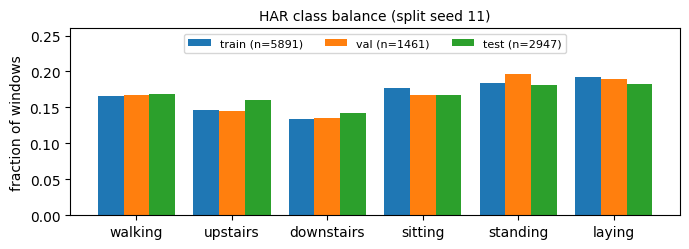

In [8]:
# class balance plot
split = har_split(SEEDS[0])
fig, ax = plt.subplots(figsize=(7, 2.6))
w = 0.27
for i, (name, labels) in enumerate([('train', split['ytr']), ('val', split['yva']), ('test', split['yte'])]):
    share = np.bincount(labels, minlength=6) / len(labels)
    ax.bar(np.arange(6) + (i - 1) * w, share, w, label=f'{name} (n={len(labels)})')
ax.set_xticks(range(6)); ax.set_xticklabels(CLASSES)
ax.set_ylim(0, 0.26); ax.set_ylabel('fraction of windows'); ax.legend(fontsize=8, ncol=3, loc='upper center')
ax.set_title(f'HAR class balance (split seed {SEEDS[0]})', fontsize=10)
plt.tight_layout(); plt.savefig(FIG / 'p1_class_balance.png', dpi=150); plt.show()

**Adding problem:** channel 0 is random numbers, channel 1 marks two positions (one in each half).
The target is the sum of the two marked numbers. Always guessing 1.0 gives MSE about 0.167, that's the baseline.
The generator is copied from the brief.

In [9]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)          # first marker, first half
    i2 = rng.integers(T // 2, T, n)          # second marker, second half
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

# tests: two markers, one in each half, target = sum of marked numbers
for T in ADD_LENGTHS:
    x, y = make_adding(1000, T, seed=0)
    marks = x[:, :, 1]
    assert np.all(marks.sum(1) == 2)
    assert np.all(marks[:, :T // 2].sum(1) == 1) and np.all(marks[:, T // 2:].sum(1) == 1)
    assert np.allclose((x[:, :, 0] * marks).sum(1), y, atol=1e-6)
x, y = make_adding(10000, 100, seed=0)
print('adding tests passed; MSE when always answering 1.0 =', round(float(((y - 1) ** 2).mean()), 4),
      '(theory: 2/12 = 0.1667)')

adding tests passed; MSE when always answering 1.0 = 0.167 (theory: 2/12 = 0.1667)


## Task 2 - Cells from scratch
Only `@`, sigmoid, tanh, + and *. One bias per gate. Shapes: x is (B, d), h is (B, h),
W_x is (G*h, d), W_h is (G*h, h), b is (G*h,), where G = 1 (RNN), 4 (LSTM) or 3 (GRU).

* RNN: h = tanh(W_x x + W_h h + b)
* LSTM: c = f*c + i*g, h = o*tanh(c)
* GRU: n = tanh(W_xn x + b_n + r*(W_hn h)), h = (1-z)*n + z*h

In [10]:
class MyCellBase(nn.Module):
    # weights shared by all three cells, gates = G
    def __init__(self, d, h, gates):
        super().__init__()
        self.d, self.h = d, h
        k = 1 / math.sqrt(h)        # same init range as PyTorch
        self.W_x = nn.Parameter(torch.empty(gates * h, d).uniform_(-k, k))   # (G*h, d)
        self.W_h = nn.Parameter(torch.empty(gates * h, h).uniform_(-k, k))   # (G*h, h)
        self.b = nn.Parameter(torch.empty(gates * h).uniform_(-k, k))        # (G*h,)

class MyRNNCell(MyCellBase):
    def __init__(self, d, h):
        super().__init__(d, h, gates=1)
    def forward(self, x, h):
        # x (B, d), h (B, h) -> (B, h)
        return torch.tanh(x @ self.W_x.T + h @ self.W_h.T + self.b)

class MyLSTMCell(MyCellBase):
    def __init__(self, d, h):
        super().__init__(d, h, gates=4)
    def forward(self, x, state):
        h, c = state                                   # each (B, h)
        z = x @ self.W_x.T + h @ self.W_h.T + self.b   # all 4 gates at once, (B, 4h)
        i, f, g, o = z.chunk(4, dim=1)                 # each (B, h), same order as PyTorch
        i, f, o = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o)
        g = torch.tanh(g)
        c = f * c + i * g                              # new cell state (B, h)
        h = o * torch.tanh(c)                          # new hidden state (B, h)
        return h, c

class MyGRUCell(MyCellBase):
    def __init__(self, d, h):
        super().__init__(d, h, gates=3)
    def forward(self, x, h):
        gx = x @ self.W_x.T                            # (B, 3h), order r, z, n
        gh = h @ self.W_h.T                            # (B, 3h)
        b_r, b_z, b_n = self.b.chunk(3)
        xr, xz, xn = gx.chunk(3, dim=1)                # each (B, h)
        hr, hz, hn = gh.chunk(3, dim=1)
        r = torch.sigmoid(xr + hr + b_r)               # reset gate
        z = torch.sigmoid(xz + hz + b_z)               # update gate
        n = torch.tanh(xn + b_n + r * hn)              # r goes on W_hn h, like PyTorch
        return (1 - z) * n + z * h                     # (B, h)

`unroll` runs a cell over the whole sequence, starting from zeros. To test my cells I copy PyTorch's
weights into them. PyTorch has two biases (b_ih, b_hh), I have one, so I add them. For the GRU this only
works if b_hn = 0, because PyTorch puts b_hn inside r*(W_hn h + b_hn).

In [11]:
def unroll(cell, x):
    # x (B, T, d) -> all hidden states (B, T, h), list of h_t, last state
    B, T, _ = x.shape
    h = x.new_zeros(B, cell.h)
    state = (h, x.new_zeros(B, cell.h)) if isinstance(cell, MyLSTMCell) else h   # lstm also needs c
    hs = []
    for t in range(T):
        state = cell(x[:, t], state)
        h = state[0] if isinstance(cell, MyLSTMCell) else state
        hs.append(h)
    return torch.stack(hs, dim=1), hs, state

@torch.no_grad()
def copy_from_library(cell, lib):
    # copy weights from a 1-layer nn.RNN / nn.LSTM / nn.GRU
    cell.W_x.copy_(lib.weight_ih_l0)
    cell.W_h.copy_(lib.weight_hh_l0)
    if isinstance(cell, MyGRUCell):
        h = cell.h
        cell.b.copy_(lib.bias_ih_l0)
        cell.b[:2 * h] += lib.bias_hh_l0[:2 * h]                # r and z biases can be added, b_hn can't
    else:
        cell.b.copy_(lib.bias_ih_l0 + lib.bias_hh_l0)

def nparams(model):
    return sum(p.numel() for p in model.parameters())

In [12]:
# tests: my cells vs PyTorch on a random batch, should match within 1e-5
set_seed(0)
d, h = 9, 64
xb = torch.randn(8, 30, d)       # (B, T, d)
rows = []
for name, Mine, Lib in [('rnn', MyRNNCell, nn.RNN), ('lstm', MyLSTMCell, nn.LSTM), ('gru', MyGRUCell, nn.GRU)]:
    lib = Lib(d, h, batch_first=True)
    if name == 'gru':
        with torch.no_grad():
            lib.bias_hh_l0[2 * h:] = 0     # b_hn = 0
    mine = Mine(d, h)
    copy_from_library(mine, lib)
    out_mine, _, last_mine = unroll(mine, xb)
    out_lib, last_lib = lib(xb)
    err = (out_mine - out_lib).abs().max().item()
    if name == 'lstm':                                          # also check the cell state c
        err = max(err, (last_mine[1] - last_lib[1][0]).abs().max().item())
    rows.append((name, err, nparams(mine), nparams(lib)))
    assert err < 1e-5, (name, err)

# just to show it: with b_hn not 0 my GRU can't match
lib = nn.GRU(d, h, batch_first=True); mine = MyGRUCell(d, h); copy_from_library(mine, lib)
gru_err_bhn = (unroll(mine, xb)[0] - lib(xb)[0]).abs().max().item()

print(pd.DataFrame(rows, columns=['cell', 'max |mine - library|', 'my params', 'library params']))
print(f'GRU when b_hn is not 0: max difference {gru_err_bhn:.2e}')
assert [r[2] for r in rows] == [4736, 18944, 14208]
assert [r[3] for r in rows] == [4800, 19200, 14400]
print('all three cells match PyTorch within 1e-5')

   cell  max |mine - library|  my params  library params
0   rnn          1.490116e-07       4736            4800
1  lstm          7.450581e-08      18944           19200
2   gru          7.450581e-08      14208           14400
GRU when b_hn is not 0: max difference 1.08e-01
all three cells match PyTorch within 1e-5


**Parameter count (d = 9, h = 64):** one gate = 64x9 + 64x64 + 64 = 4,736.
RNN = 4,736, LSTM = 4 x 4,736 = 18,944, GRU = 3 x 4,736 = 14,208.
PyTorch has one more bias per gate, so 4,800, 19,200 and 14,400.

## Model for tasks 3-5
Here I use PyTorch's `nn.RNN`, `nn.LSTM`, `nn.GRU` (allowed, and much faster). One recurrent layer and a
linear layer on the last time step. Same recipe for every model: Adam 1e-3, batch 64, clip 1.0.
I keep the epoch with the lowest validation loss and use the test set only once at the end.

In [13]:
class SeqModel(nn.Module):
    def __init__(self, kind, d_in, hidden, n_out):
        super().__init__()
        self.kind = kind
        layer = {'rnn': nn.RNN, 'lstm': nn.LSTM, 'gru': nn.GRU}[kind]
        self.rnn = layer(d_in, hidden, batch_first=True)
        self.head = nn.Linear(hidden, n_out)
    def forward(self, x):                 # x (B, T, d_in)
        out, _ = self.rnn(x)              # (B, T, hidden)
        return self.head(out[:, -1])      # last step only -> (B, n_out)

def to_loader(X, y, shuffle, seed=0, bs=BATCH):
    ds = torch.utils.data.TensorDataset(torch.as_tensor(X), torch.as_tensor(y))
    g = torch.Generator().manual_seed(seed)      # fixed shuffle order
    return torch.utils.data.DataLoader(ds, batch_size=bs, shuffle=shuffle, generator=g)

In [14]:
@torch.no_grad()
def evaluate(model, loader, task):
    # 'cls': loss, accuracy, macro-F1 and predictions; 'reg': MSE
    model.eval()
    losses, preds, ys = [], [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        if task == 'cls':
            losses.append(F.cross_entropy(out, yb, reduction='sum').item())
            preds.append(out.argmax(1).cpu())
        else:
            losses.append(F.mse_loss(out.squeeze(1), yb, reduction='sum').item())
        ys.append(yb.cpu())
    n = sum(len(y) for y in ys)
    res = {'loss': sum(losses) / n}
    if task == 'cls':
        p, t = torch.cat(preds).numpy(), torch.cat(ys).numpy()
        res.update(acc=(p == t).mean(), f1=f1_score(t, p, average='macro'), pred=p, true=t)
    return res

def train(model, train_loader, val_loader, task, epochs, clip=CLIP):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {'train': [], 'val': []}
    best, best_state, best_ep, t_total = float('inf'), None, -1, 0.0
    for ep in range(epochs):
        model.train(); t0 = time.time(); total, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = F.cross_entropy(out, yb) if task == 'cls' else F.mse_loss(out.squeeze(1), yb)
            opt.zero_grad(); loss.backward()
            if clip is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            total += loss.item() * len(yb); n += len(yb)
        if device.type == 'cuda':
            torch.cuda.synchronize()                    # so the timing is right on GPU
        t_total += time.time() - t0
        v = evaluate(model, val_loader, task)['loss']
        hist['train'].append(total / n); hist['val'].append(v)
        if v < best:                                    # keep the best epoch
            best, best_ep = v, ep + 1
            best_state = {k: t.detach().clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    return dict(hist=hist, best_epoch=best_ep, sec_per_epoch=t_total / epochs, state=best_state)

## Task 3 - HAR classification
Same settings for all three models, 3 seeds each. I report accuracy and macro-F1 (F1 averaged over the 6 classes).

In [15]:
def train_har(kind, seed, hidden):
    split = har_split(seed)
    set_seed(seed)
    model = SeqModel(kind, 9, hidden, 6)              # 9 channels in, 6 classes out
    train_loader = to_loader(split['Xtr'], split['ytr'], True, seed)
    val_loader = to_loader(split['Xva'], split['yva'], False)
    test_loader = to_loader(split['Xte'], split['yte'], False)
    r = train(model, train_loader, val_loader, 'cls', HAR_EPOCHS)
    ev = evaluate(model, test_loader, 'cls')          # test set used once, here
    return dict(kind=kind, seed=seed, hidden=hidden, acc=ev['acc'], f1=ev['f1'], params=nparams(model),
                sec=r['sec_per_epoch'], pred=ev['pred'], true=ev['true'], hist=r['hist'],
                best_epoch=r['best_epoch'], val_subj=split['val_subj'])

def run_har(kind, seed, hidden, problem='problem1_har'):
    # train (or load from cache) and write one row to results.csv
    r = cached(f'har_{kind}_h{hidden}_s{seed}_e{HAR_EPOCHS}', lambda: train_har(kind, seed, hidden))
    log_result(problem=problem, model=kind, seed=seed, seq_len=128, test_acc=round(r['acc'], 4),
               macro_f1=round(r['f1'], 4), params=r['params'], sec_per_epoch=round(r['sec'], 3),
               notes=f'hidden={hidden}; epochs={HAR_EPOCHS}; best_epoch={r["best_epoch"]}; '
                     f'val_subjects={"-".join(map(str, r["val_subj"]))}; selection=min_val_loss; hw={r["hw"]}')
    print(f'{problem} {kind:4s} h={hidden:3d} seed={seed}: acc={r["acc"]:.4f} f1={r["f1"]:.4f} '
          f'best_ep={r["best_epoch"]} {r["sec"]:.2f}s/ep')
    return r

In [16]:
# 3 models x 3 seeds
har_runs = [run_har(k, s, HIDDEN) for s in SEEDS for k in ['rnn', 'lstm', 'gru']]

problem1_har rnn  h= 64 seed=11: acc=0.8683 f1=0.8690 best_ep=24 0.36s/ep
problem1_har lstm h= 64 seed=11: acc=0.8867 f1=0.8873 best_ep=8 0.34s/ep
problem1_har gru  h= 64 seed=11: acc=0.8877 f1=0.8865 best_ep=6 0.31s/ep
problem1_har rnn  h= 64 seed=23: acc=0.8806 f1=0.8803 best_ep=30 0.30s/ep
problem1_har lstm h= 64 seed=23: acc=0.9016 f1=0.9025 best_ep=28 0.34s/ep
problem1_har gru  h= 64 seed=23: acc=0.8955 f1=0.8962 best_ep=26 0.33s/ep
problem1_har rnn  h= 64 seed=37: acc=0.8388 f1=0.8368 best_ep=30 0.29s/ep
problem1_har lstm h= 64 seed=37: acc=0.8979 f1=0.8973 best_ep=23 0.32s/ep
problem1_har gru  h= 64 seed=37: acc=0.9013 f1=0.9012 best_ep=14 0.33s/ep


In [17]:
# table: mean ± std over the seeds
def mean_std(values):
    v = np.asarray(values, dtype=float)
    return f'{v.mean():.4f} ± {v.std(ddof=1) if len(v) > 1 else 0:.4f}'   # sample std

har_df = pd.DataFrame([{k: r[k] for k in ['kind', 'seed', 'acc', 'f1', 'params', 'sec']} for r in har_runs])
har_table = har_df.groupby('kind', sort=False).agg(
    test_acc=('acc', mean_std), macro_f1=('f1', mean_std), params=('params', 'first'),
    sec_per_epoch=('sec', lambda v: f'{np.mean(v):.2f}'))
print(har_table)
har_table.to_csv(FIG / 'p1_har_table.csv')

             test_acc         macro_f1  params sec_per_epoch
kind                                                        
rnn   0.8626 ± 0.0215  0.8620 ± 0.0225    5190          0.32
lstm  0.8954 ± 0.0078  0.8957 ± 0.0077   19590          0.33
gru   0.8948 ± 0.0068  0.8946 ± 0.0075   14790          0.32


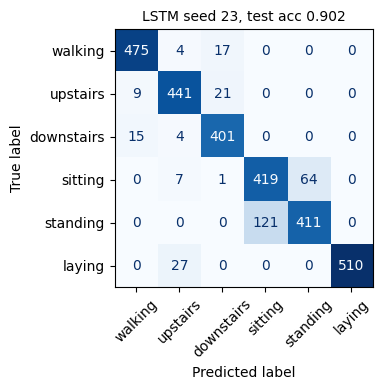

best model: lstm seed 23


In [18]:
# confusion matrix of the best model (best mean accuracy, then its best seed)
best_kind = har_df.groupby('kind')['acc'].mean().idxmax()
best_run = max([r for r in har_runs if r['kind'] == best_kind], key=lambda r: r['acc'])
cm = confusion_matrix(best_run['true'], best_run['pred'])
fig, ax = plt.subplots(figsize=(4.6, 4.0))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False, xticks_rotation=45)
ax.set_title(f'{best_kind.upper()} seed {best_run["seed"]}, test acc {best_run["acc"]:.3f}', fontsize=10)
plt.tight_layout(); plt.savefig(FIG / 'p1_confusion_best.png', dpi=150); plt.show()
print('best model:', best_kind, 'seed', best_run['seed'])

## Task 4 - Adding problem
10,000 train / 1,000 val / 1,000 test sequences (seeds 0/1/2) for each T. Same budget for every model.
I call a run solved if the test MSE is below 0.05.

In [19]:
LENGTHS_NEEDED = sorted(set(ADD_LENGTHS) | {100, 200})    # 100 is used in 5a, 200 in 5c
adding_data = {T: [make_adding(n, T, s) for n, s in [(10000, 0), (1000, 1), (1000, 2)]] for T in LENGTHS_NEEDED}
BASELINE = {T: float(((adding_data[T][2][1] - 1.0) ** 2).mean()) for T in LENGTHS_NEEDED}   # always guess 1.0
print('baseline test MSE (always answer 1.0):', {T: round(v, 4) for T, v in BASELINE.items()})

def train_adding(kind, seed, T, clip, forget_bias):
    (Xa, ya), (Xv, yv), (Xt, yt) = adding_data[T]
    set_seed(seed)
    model = SeqModel(kind, 2, HIDDEN, 1)                      # 2 channels in, 1 number out
    if forget_bias is not None:      # only for the odd-digit ablation
        with torch.no_grad():
            h = HIDDEN
            model.rnn.bias_ih_l0[h:2 * h] = forget_bias       # gate order i, f, g, o -> f is the 2nd block
            model.rnn.bias_hh_l0[h:2 * h] = 0.0
    r = train(model, to_loader(Xa, ya, True, seed), to_loader(Xv, yv, False), 'reg', ADD_EPOCHS, clip=clip)
    mse = evaluate(model, to_loader(Xt, yt, False), 'reg')['loss']
    return dict(kind=kind, seed=seed, T=T, mse=mse, hist=r['hist'], best_epoch=r['best_epoch'],
                state={k: v.cpu() for k, v in r['state'].items()}, sec=r['sec_per_epoch'], params=nparams(model))

def run_adding(kind, seed, T, clip=CLIP, forget_bias=None, problem='problem1_adding', extra=''):
    name = f'add_{kind}_T{T}_s{seed}_e{ADD_EPOCHS}_clip{clip}_fb{forget_bias}'
    r = cached(name, lambda: train_adding(kind, seed, T, clip, forget_bias))
    log_result(problem=problem, model=kind, seed=seed, seq_len=T, test_mse=round(r['mse'], 5), params=r['params'],
               sec_per_epoch=round(r['sec'], 3),
               notes=f'hidden={HIDDEN}; epochs={ADD_EPOCHS}; best_epoch={r["best_epoch"]}; clip={clip}; '
                     f'solved={r["mse"] < 0.05}; selection=min_val_mse{extra}; hw={r["hw"]}')
    print(f'{problem} {kind:4s} T={T:3d} seed={seed}: test MSE={r["mse"]:.4f} (baseline {BASELINE[T]:.4f}) '
          f'{r["sec"]:.1f}s/ep')
    return r

baseline test MSE (always answer 1.0): {50: 0.1754, 100: 0.1697, 200: 0.1679, 400: 0.1527}


In [20]:
# 4 lengths x 3 models x 3 seeds = 36 runs
add_runs = []
for T in ADD_LENGTHS:
    for s in SEEDS:
        for k in ['rnn', 'lstm', 'gru']:
            add_runs.append(run_adding(k, s, T))

problem1_adding rnn  T= 50 seed=11: test MSE=0.0084 (baseline 0.1754) 0.5s/ep
problem1_adding lstm T= 50 seed=11: test MSE=0.0002 (baseline 0.1754) 0.5s/ep
problem1_adding gru  T= 50 seed=11: test MSE=0.0001 (baseline 0.1754) 0.5s/ep
problem1_adding rnn  T= 50 seed=23: test MSE=0.0113 (baseline 0.1754) 0.5s/ep
problem1_adding lstm T= 50 seed=23: test MSE=0.0001 (baseline 0.1754) 0.5s/ep
problem1_adding gru  T= 50 seed=23: test MSE=0.0001 (baseline 0.1754) 0.5s/ep
problem1_adding rnn  T= 50 seed=37: test MSE=0.0090 (baseline 0.1754) 0.5s/ep
problem1_adding lstm T= 50 seed=37: test MSE=0.0002 (baseline 0.1754) 0.5s/ep
problem1_adding gru  T= 50 seed=37: test MSE=0.0001 (baseline 0.1754) 0.5s/ep
problem1_adding rnn  T=100 seed=11: test MSE=0.1627 (baseline 0.1697) 0.5s/ep
problem1_adding lstm T=100 seed=11: test MSE=0.0002 (baseline 0.1697) 0.5s/ep
problem1_adding gru  T=100 seed=11: test MSE=0.0001 (baseline 0.1697) 0.5s/ep
problem1_adding rnn  T=100 seed=23: test MSE=0.1663 (baseline 0.

In [21]:
# tables: MSE, how many seeds solved it, first epoch under 0.05
add_df = pd.DataFrame([{k: r[k] for k in ['kind', 'seed', 'T', 'mse', 'sec']} for r in add_runs])
mse_table = add_df.pivot_table(index='kind', columns='T', values='mse', aggfunc=mean_std, sort=False)
solved_table = add_df.assign(solved=add_df.mse < 0.05).pivot_table(
    index='kind', columns='T', values='solved', aggfunc='sum', sort=False).astype(int).astype(str) + f'/{len(SEEDS)}'
print('test MSE (mean ± std over seeds); baseline ~0.167\n', mse_table)
print('\nsolved runs (test MSE < 0.05)\n', solved_table)

def first_below(hist, limit=0.05):
    # first epoch with val MSE under the limit, '-' if never
    return next((str(i + 1) for i, v in enumerate(hist['val']) if v < limit), '-')

print('\nfirst epoch with validation MSE < 0.05, per seed:')
for T in ADD_LENGTHS:
    print(f'  T={T:3d}', {k: [first_below(r['hist']) for r in add_runs if r['kind'] == k and r['T'] == T]
                          for k in ['rnn', 'lstm', 'gru']})
mse_table.to_csv(FIG / 'p1_adding_mse_table.csv'); solved_table.to_csv(FIG / 'p1_adding_solved_table.csv')

test MSE (mean ± std over seeds); baseline ~0.167
 T                 50               100              200              400
kind                                                                    
rnn   0.0096 ± 0.0015  0.1496 ± 0.0259  0.1682 ± 0.0002  0.1541 ± 0.0005
lstm  0.0002 ± 0.0000  0.0007 ± 0.0007  0.0016 ± 0.0009  0.1537 ± 0.0002
gru   0.0001 ± 0.0000  0.0001 ± 0.0001  0.0001 ± 0.0001  0.0004 ± 0.0001

solved runs (test MSE < 0.05)
 T     50   100  200  400
kind                    
rnn   3/3  0/3  0/3  0/3
lstm  3/3  3/3  3/3  0/3
gru   3/3  3/3  3/3  3/3

first epoch with validation MSE < 0.05, per seed:
  T= 50 {'rnn': ['24', '30', '23'], 'lstm': ['13', '14', '13'], 'gru': ['5', '5', '5']}
  T=100 {'rnn': ['-', '-', '-'], 'lstm': ['24', '26', '25'], 'gru': ['7', '7', '6']}
  T=200 {'rnn': ['-', '-', '-'], 'lstm': ['41', '34', '40'], 'gru': ['9', '9', '10']}
  T=400 {'rnn': ['-', '-', '-'], 'lstm': ['-', '-', '-'], 'gru': ['16', '14', '14']}


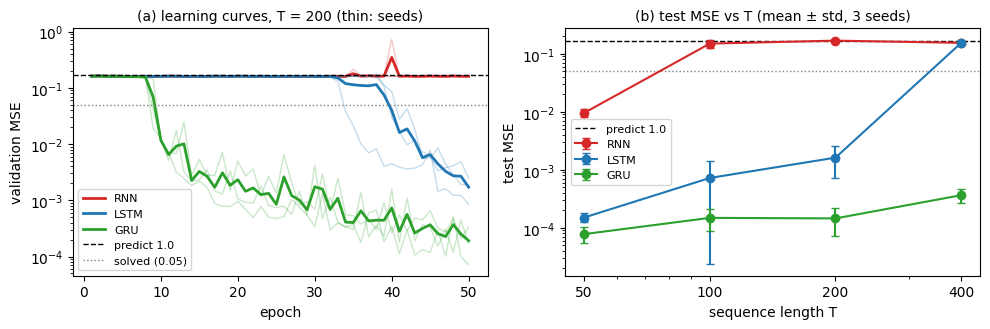

In [22]:
# plots: learning curves at T = 200, and test MSE vs T
colors = {'rnn': 'tab:red', 'lstm': 'tab:blue', 'gru': 'tab:green'}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
T_CURVE = 200 if 200 in ADD_LENGTHS else ADD_LENGTHS[-1]
for k in ['rnn', 'lstm', 'gru']:
    curves = np.array([r['hist']['val'] for r in add_runs if r['kind'] == k and r['T'] == T_CURVE])
    ep = np.arange(1, curves.shape[1] + 1)
    for c in curves:                                            # thin = one seed
        ax.plot(ep, c, color=colors[k], alpha=0.25, lw=1)
    ax.plot(ep, curves.mean(0), color=colors[k], lw=2, label=k.upper())   # thick = mean
ax.axhline(BASELINE[T_CURVE], ls='--', color='k', lw=1, label='predict 1.0')
ax.axhline(0.05, ls=':', color='gray', lw=1, label='solved (0.05)')
ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('validation MSE')
ax.set_title(f'(a) learning curves, T = {T_CURVE} (thin: seeds)', fontsize=10); ax.legend(fontsize=8)
ax = axes[1]
for k in ['rnn', 'lstm', 'gru']:
    g = add_df[add_df.kind == k].groupby('T')['mse']
    ax.errorbar(g.mean().index, g.mean(), yerr=g.std(ddof=1), marker='o', capsize=3, color=colors[k], label=k.upper())
ax.axhline(np.mean([BASELINE[T] for T in ADD_LENGTHS]), ls='--', color='k', lw=1, label='predict 1.0')
ax.axhline(0.05, ls=':', color='gray', lw=1)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xticks(ADD_LENGTHS); ax.set_xticklabels(ADD_LENGTHS)
ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel('sequence length T'); ax.set_ylabel('test MSE'); ax.legend(fontsize=8)
ax.set_title('(b) test MSE vs T (mean ± std, 3 seeds)', fontsize=10)
plt.tight_layout(); plt.savefig(FIG / 'p1_adding_curves_mse.png', dpi=150); plt.show()

## Task 5 - Gradients, ablations and analysis
### (a) ||dL/dh_t|| at T = 100
If the gradient is tiny for early steps, the model can't learn from them (vanishing gradient).
I step the PyTorch layer one step at a time and use `retain_grad()` to keep the gradient of each h_t.
Loss = sum of squared errors over 256 validation sequences. I plot it before and after training.

rnn: ||dL/dh_1|| / ||dL/dh_100|| before = 5.53e-22, after = 5.28e-03
lstm: ||dL/dh_1|| / ||dL/dh_100|| before = 8.06e-21, after = 1.60e-01
gru: ||dL/dh_1|| / ||dL/dh_100|| before = 7.19e-21, after = 2.89e-01


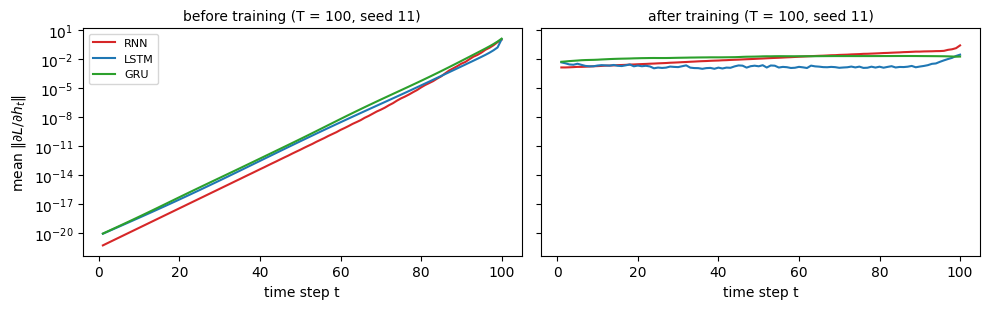

In [23]:
def grad_norms(model, X, y):
    model.to(device).train()   # cuDNN backward needs train mode (no dropout here, so no change)
    X, y = torch.as_tensor(X).to(device), torch.as_tensor(y).to(device)
    B, T, _ = X.shape
    h = torch.zeros(1, B, HIDDEN, device=device)
    state = (h, torch.zeros_like(h)) if model.kind == 'lstm' else h
    hs = []
    for t in range(T):
        _, state = model.rnn(X[:, t:t + 1], state)               # one step
        h_t = state[0] if model.kind == 'lstm' else state
        h_t.retain_grad(); hs.append(h_t)
    loss = ((model.head(hs[-1][0]).squeeze(1) - y) ** 2).sum()
    loss.backward()
    return np.array([hh.grad[0].norm(dim=1).mean().item() for hh in hs])   # one value per step

Xg, yg = adding_data[100][1][0][:256], adding_data[100][1][1][:256]
gn = {}
for k in ['rnn', 'lstm', 'gru']:
    set_seed(SEEDS[0]); fresh = SeqModel(k, 2, HIDDEN, 1)       # untrained
    gn[(k, 'before')] = grad_norms(fresh, Xg, yg)
    trained = SeqModel(k, 2, HIDDEN, 1)                         # trained T = 100 model, first seed
    trained.load_state_dict(next(r['state'] for r in add_runs if r['kind'] == k and r['T'] == 100 and r['seed'] == SEEDS[0]))
    gn[(k, 'after')] = grad_norms(trained, Xg, yg)
    print(f'{k}: ||dL/dh_1|| / ||dL/dh_100|| before = {gn[(k, "before")][0] / gn[(k, "before")][-1]:.2e}, '
          f'after = {gn[(k, "after")][0] / gn[(k, "after")][-1]:.2e}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, when in zip(axes, ['before', 'after']):
    for k in ['rnn', 'lstm', 'gru']:
        ax.plot(np.arange(1, 101), gn[(k, when)], color=colors[k], label=k.upper())
    ax.set_yscale('log'); ax.set_xlabel('time step t'); ax.set_title(f'{when} training (T = 100, seed {SEEDS[0]})', fontsize=10)
axes[0].set_ylabel(r'mean $\|\partial L / \partial h_t\|$'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG / 'p1_grad_norms.png', dpi=150); plt.show()

### (b) Hidden size sweep on HAR
LSTM and GRU with h = 16, 32, 64, 128. Same settings as task 3, and the h = 64 runs are reused from there.

problem1_har_sweep lstm h= 16 seed=11: acc=0.8660 f1=0.8658 best_ep=24 0.32s/ep
problem1_har_sweep gru  h= 16 seed=11: acc=0.8721 f1=0.8721 best_ep=15 0.33s/ep
problem1_har_sweep lstm h= 16 seed=23: acc=0.8999 f1=0.9003 best_ep=20 0.35s/ep
problem1_har_sweep gru  h= 16 seed=23: acc=0.8968 f1=0.8966 best_ep=30 0.33s/ep
problem1_har_sweep lstm h= 16 seed=37: acc=0.8629 f1=0.8621 best_ep=17 0.34s/ep
problem1_har_sweep gru  h= 16 seed=37: acc=0.8782 f1=0.8773 best_ep=28 0.31s/ep
problem1_har_sweep lstm h= 32 seed=11: acc=0.8412 f1=0.8406 best_ep=9 0.35s/ep
problem1_har_sweep gru  h= 32 seed=11: acc=0.8829 f1=0.8849 best_ep=7 0.33s/ep
problem1_har_sweep lstm h= 32 seed=23: acc=0.8839 f1=0.8844 best_ep=21 0.35s/ep
problem1_har_sweep gru  h= 32 seed=23: acc=0.8935 f1=0.8941 best_ep=12 0.32s/ep
problem1_har_sweep lstm h= 32 seed=37: acc=0.8863 f1=0.8860 best_ep=28 0.32s/ep
problem1_har_sweep gru  h= 32 seed=37: acc=0.8860 f1=0.8849 best_ep=12 0.33s/ep
problem1_har_sweep lstm h=128 seed=11: acc

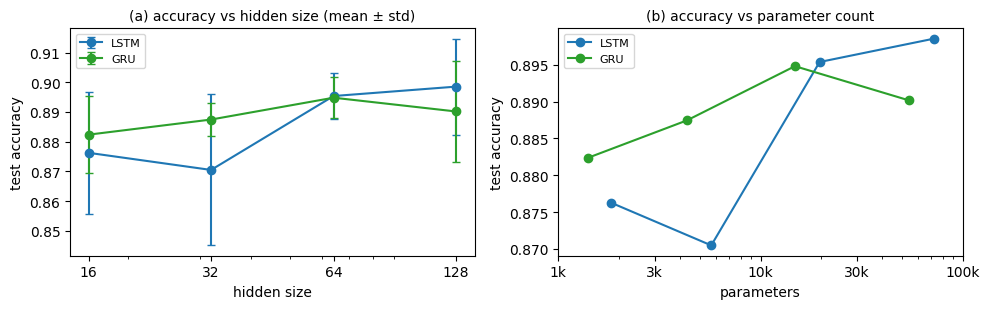

In [24]:
sweep_runs = [r for r in har_runs if r['kind'] in ('lstm', 'gru') and r['hidden'] in SWEEP_SIZES]
for size in SWEEP_SIZES:
    if size == HIDDEN:
        continue                                                # done in task 3
    for s in SEEDS:
        for k in ['lstm', 'gru']:
            sweep_runs.append(run_har(k, s, size, problem='problem1_har_sweep'))

sw = pd.DataFrame([{k: r[k] for k in ['kind', 'hidden', 'seed', 'acc', 'f1', 'params', 'sec']} for r in sweep_runs])
sweep_table = sw.groupby(['kind', 'hidden']).agg(test_acc=('acc', mean_std), macro_f1=('f1', mean_std),
                                                 params=('params', 'first'), sec_per_epoch=('sec', lambda v: f'{np.mean(v):.2f}'))
print(sweep_table); sweep_table.to_csv(FIG / 'p1_sweep_table.csv')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for k in ['lstm', 'gru']:
    g = sw[sw.kind == k].groupby('hidden')
    axes[0].errorbar(g['acc'].mean().index, g['acc'].mean(), yerr=g['acc'].std(ddof=1), marker='o', capsize=3,
                     color=colors[k], label=k.upper())
    axes[1].plot(g['params'].first(), g['acc'].mean(), marker='o', color=colors[k], label=k.upper())
for ax in axes:
    ax.set_xscale('log'); ax.set_ylabel('test accuracy'); ax.legend(fontsize=8)
    ax.xaxis.set_minor_formatter(NullFormatter())
axes[0].set_xticks(SWEEP_SIZES); axes[0].set_xticklabels(SWEEP_SIZES); axes[0].set_xlabel('hidden size')
axes[1].set_xticks([1e3, 3e3, 1e4, 3e4, 1e5]); axes[1].set_xticklabels(['1k', '3k', '10k', '30k', '100k'])
axes[0].set_title('(a) accuracy vs hidden size (mean ± std)', fontsize=10)
axes[1].set_xlabel('parameters'); axes[1].set_title('(b) accuracy vs parameter count', fontsize=10)
plt.tight_layout(); plt.savefig(FIG / 'p1_hidden_sweep.png', dpi=150); plt.show()

### (c) My ablation at T = 200
Even last digit: RNN with clipping 1.0 vs no clipping. Odd: LSTM forget-gate bias 0 vs 1.
My ID ends in 0, so I do the clipping one. The clipped runs are the same as in task 4, only "no clipping" is new.

problem1_ablation_clip rnn  T=200 seed=11: test MSE=0.1685 (baseline 0.1679) 0.4s/ep
problem1_ablation_clip rnn  T=200 seed=23: test MSE=0.1682 (baseline 0.1679) 0.4s/ep
problem1_ablation_clip rnn  T=200 seed=37: test MSE=0.1681 (baseline 0.1679) 0.4s/ep
  model      setting         test MSE solved  \
0   rnn     clip 1.0  0.1682 ± 0.0002    0/3   
1   rnn  no clipping  0.1683 ± 0.0002    0/3   

  first epoch val MSE < 0.05 (per seed)  
0                               -, -, -  
1                               -, -, -  


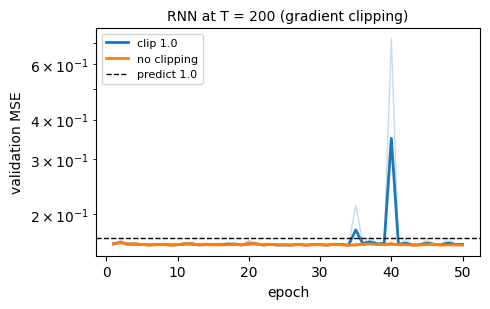

In [25]:
run_even = ID_LAST_DIGIT is None or ID_LAST_DIGIT % 2 == 0     # None runs both
run_odd = ID_LAST_DIGIT is None or ID_LAST_DIGIT % 2 == 1
abl = {}
if run_even:
    abl[('rnn', 'clip 1.0')] = ([r for r in add_runs if r['kind'] == 'rnn' and r['T'] == 200] or
                                [run_adding('rnn', s, 200, problem='problem1_ablation_clip', extra='; ablation=clip_1.0')
                                 for s in SEEDS])
    abl[('rnn', 'no clipping')] = [run_adding('rnn', s, 200, clip=None, problem='problem1_ablation_clip',
                                              extra='; ablation=no_clipping') for s in SEEDS]
if run_odd:
    for fb in [0.0, 1.0]:
        abl[('lstm', f'forget bias {fb:.0f}')] = [run_adding('lstm', s, 200, forget_bias=fb, problem='problem1_ablation_forget_bias',
                                                             extra=f'; ablation=forget_bias_{fb:.0f}') for s in SEEDS]

rows = [(k, setting, mean_std([r['mse'] for r in rs]), f"{sum(r['mse'] < 0.05 for r in rs)}/{len(rs)}",
         ', '.join(first_below(r['hist']) for r in rs)) for (k, setting), rs in abl.items()]
abl_table = pd.DataFrame(rows, columns=['model', 'setting', 'test MSE', 'solved', 'first epoch val MSE < 0.05 (per seed)'])
print(abl_table); abl_table.to_csv(FIG / 'p1_ablation_table.csv', index=False)

panels = [p for p, on in [('rnn', run_even), ('lstm', run_odd)] if on]
fig, axes = plt.subplots(1, len(panels), figsize=(5 * len(panels), 3.2), squeeze=False)
for ax, k in zip(axes[0], panels):
    for (kk, setting), rs in abl.items():
        if kk != k:
            continue
        c = np.array([r['hist']['val'] for r in rs]); ep = np.arange(1, c.shape[1] + 1)
        line, = ax.plot(ep, c.mean(0), lw=2, label=setting)
        for cc in c:
            ax.plot(ep, cc, color=line.get_color(), alpha=0.25, lw=1)
    ax.axhline(BASELINE[200], ls='--', color='k', lw=1, label='predict 1.0')
    ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('validation MSE'); ax.legend(fontsize=8)
    ax.set_title(f'{k.upper()} at T = 200 ({"gradient clipping" if k == "rnn" else "forget-gate bias"})', fontsize=10)
plt.tight_layout(); plt.savefig(FIG / 'p1_ablation.png', dpi=150); plt.show()

### (d) Analysis
The write-up is in the report, section 1.6.

In [26]:
print(pd.read_csv(RESULTS).query("problem.str.startswith('problem1')", engine='python').shape[0], 'problem 1 rows in results.csv')

66 problem 1 rows in results.csv
